# EP2 – Pipeline Batch con PySpark (US Accidents 2016–2023)
**Big Data y sus Aplicaciones – AID-2504 · ITCJ**

**Pregunta de negocio (EP1):** ¿En qué estados, horas y condiciones climáticas se concentran los accidentes y los más severos?

**Dataset:** US Accidents (Kaggle), 7,728,394 registros × 46 columnas, 2,916.5 MB en CSV.

In [2]:
import sys, pyspark
print(sys.executable)
print(pyspark.__version__)

c:\Users\aleja\Desktop\work\.venv311\Scripts\python.exe
3.5.3


## Etapa 0 – Setup y configuración

In [1]:
import os, sys, time, re
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Binarios de Hadoop requeridos por Spark en Windows para escribir en disco local
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import *
from pyspark.sql.window import Window

# Rutas del pipeline
BASE_PATH   = "outputs"
RUTA_ORIGEN = "datasets/US_Accidents_March23.csv"
RUTA_BRONZE = f"{BASE_PATH}/bronze/dataset_bronze.parquet"
RUTA_SILVER = f"{BASE_PATH}/silver/dataset_silver.parquet"
RUTA_GOLD   = f"{BASE_PATH}/gold"

# Parámetros de Spark
DRIVER_MEM    = "6g"
SHUFFLE_PARTS = "16"

try:
    spark.stop()
except NameError:
    pass

spark = (SparkSession.builder
    .appName("EP2-Pipeline")
    .master("local[*]")
    .config("spark.driver.memory", DRIVER_MEM)
    .config("spark.sql.shuffle.partitions", SHUFFLE_PARTS)
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.sql.parquet.filterPushdown", "true")
    .getOrCreate())

print("Spark", spark.version, "| Spark UI: http://localhost:4040")
print("Directorio actual:", os.getcwd())
print("CSV existe:", os.path.exists(RUTA_ORIGEN))

Spark 3.5.3 | Spark UI: http://localhost:4040
Directorio actual: c:\Users\aleja\Desktop\work
CSV existe: True


### Justificación de parámetros
- **`spark.driver.memory = 6g`**: en modo `local[*]` el driver ejecuta todo el trabajo. Se necesita memoria para el cache de Silver (545.6 MB en Parquet comprimido, bastante más al descomprimirse en memoria) y para los shuffles de las agregaciones. 6 GB evita derrames a disco y deja memoria libre para el sistema operativo.
- **`spark.sql.shuffle.partitions = 16`**: el valor por defecto (200) crea 200 tareas por shuffle. En una sola máquina, y con agregaciones cuyo resultado es pequeño (por estado, año u hora), casi todas quedarían vacías y el costo de planificarlas superaría el trabajo útil. Con 16 se reparte el trabajo entre los hilos locales sin ese overhead.
- **`spark.sql.adaptive.enabled = true` (AQE)**: Spark re-optimiza el plan durante la ejecución con estadísticas reales (junta particiones pequeñas tras un shuffle y puede cambiar el tipo de join). No tiene desventajas relevantes y es obligatorio en el lab.
- **`spark.sql.parquet.filterPushdown = true`**: los filtros se evalúan dentro del lector de Parquet usando las estadísticas de cada bloque, evitando cargar filas que luego se descartarían.
- **`HADOOP_HOME` con `winutils.exe` y `hadoop.dll`**: en Windows, Spark los necesita para escribir archivos en el sistema de archivos local; sin ellos falla la escritura de Parquet.

## Etapa 1 – Ingesta (Zona Bronze)

In [2]:
schema = StructType([
    StructField("ID", StringType()), StructField("Source", StringType()),
    StructField("Severity", IntegerType()),
    StructField("Start_Time", StringType()), StructField("End_Time", StringType()),
    StructField("Start_Lat", DoubleType()), StructField("Start_Lng", DoubleType()),
    StructField("End_Lat", DoubleType()), StructField("End_Lng", DoubleType()),
    StructField("Distance_mi", DoubleType()), StructField("Description", StringType()),
    StructField("Street", StringType()), StructField("City", StringType()),
    StructField("County", StringType()), StructField("State", StringType()),
    StructField("Zipcode", StringType()), StructField("Country", StringType()),
    StructField("Timezone", StringType()), StructField("Airport_Code", StringType()),
    StructField("Weather_Timestamp", StringType()),
    StructField("Temperature_F", DoubleType()), StructField("Wind_Chill_F", DoubleType()),
    StructField("Humidity_pct", DoubleType()), StructField("Pressure_in", DoubleType()),
    StructField("Visibility_mi", DoubleType()), StructField("Wind_Direction", StringType()),
    StructField("Wind_Speed_mph", DoubleType()), StructField("Precipitation_in", DoubleType()),
    StructField("Weather_Condition", StringType()),
] + [StructField(c, BooleanType()) for c in [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
    "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]]
  + [StructField(c, StringType()) for c in [
    "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]])

# Validación de columnas: el schema se asigna por posición
with open(RUTA_ORIGEN, encoding="utf-8") as f:
    header = f.readline().strip().split(",")
norm = lambda s: re.sub(r"[^0-9a-zA-Z]+", "_", s).strip("_").lower()
print(f"Columnas en CSV: {len(header)} | en schema: {len(schema.fields)}")
problemas = [(h, c) for h, c in zip(header, schema.fieldNames()) if not norm(c).startswith(norm(h))]
print("Columnas con orden/nombre distinto:", problemas if problemas else "ninguna")
assert len(header) == len(schema.fields), "El número de columnas no coincide con el schema"

Columnas en CSV: 46 | en schema: 46
Columnas con orden/nombre distinto: ninguna


In [3]:
# Lectura con schema explícito
df_bronze = (spark.read.schema(schema)
             .option("header", "true")
             .csv(RUTA_ORIGEN))

print(f"Bronze: {df_bronze.count():,} filas × {len(df_bronze.columns)} columnas")
df_bronze.printSchema()
df_bronze.show(3, truncate=False)

Bronze: 7,728,394 filas × 46 columnas
root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: string (nullable = true)
 |-- End_Time: string (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- End_Lat: double (nullable = true)
 |-- End_Lng: double (nullable = true)
 |-- Distance_mi: double (nullable = true)
 |-- Description: string (nullable = true)
 |-- Street: string (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Weather_Timestamp: string (nullable = true)
 |-- Temperature_F: double (nullable = true)
 |-- Wind_Chill_F: double (nullable = true)
 |-- Humidity_pct: double (nullable = true)
 |-- Pressure_in: doubl

In [4]:
# Escritura en Parquet (zona Bronze)
t0 = time.time()
df_bronze.write.mode("overwrite").parquet(RUTA_BRONZE)
print(f"Bronze escrito en {time.time()-t0:.2f}s")

# Comparación de tamaño CSV vs Parquet
tam_csv = os.path.getsize(RUTA_ORIGEN) / 1024 / 1024
tam_parquet = sum(os.path.getsize(os.path.join(r, f))
                  for r, _, fs in os.walk(RUTA_BRONZE) for f in fs) / 1024 / 1024
print(f"CSV: {tam_csv:.1f} MB → Parquet: {tam_parquet:.1f} MB (ratio: {tam_csv/tam_parquet:.1f}x)")

Bronze escrito en 46.24s
CSV: 2916.5 MB → Parquet: 743.3 MB (ratio: 3.9x)


### Justificación Bronze
- **Schema explícito en lugar de `inferSchema`**: inferir obliga a leer todo el archivo dos veces (una para inferir y otra para cargar), lo que con 7.7 M de filas es lento, y además puede adivinar mal los tipos. Con el schema explícito la lectura es de una sola pasada y los tipos son reproducibles. La validación confirmó 46 columnas en el CSV y en el schema, sin diferencias de orden.
- **Fechas como `StringType` en Bronze**: Bronze es el dato crudo sin transformar. Algunas fechas pueden traer fracciones de segundo y un parseo fallido las convertiría en `null` en silencio. La conversión a timestamp se hace en Silver.
- **Columnas con unidades renombradas** (`Distance(mi)` → `Distance_mi`, `Humidity(%)` → `Humidity_pct`): Parquet no admite paréntesis ni `%` en los nombres. Es un cambio de nombre, no de contenido, y funciona porque con schema explícito Spark asigna los nombres por posición.
- **Parquet frente a CSV**: formato columnar y comprimido que conserva el schema y permite leer solo las columnas necesarias y aplicar predicate pushdown. Resultado medido: **2,916.5 MB → 743.3 MB (ratio 3.9x, 74.5 % menos espacio)**, con 7,728,394 filas escritas en 35.83 s.

## Etapa 2 – Limpieza y calidad (Zona Silver)

In [5]:
# Diagnóstico de calidad sobre Bronze
df_raw = spark.read.parquet(RUTA_BRONZE)
total = df_raw.count()
print(f"Total registros: {total:,}")

nulos = df_raw.select([(F.sum(F.col(c).isNull().cast("int")) / total * 100).alias(c) for c in df_raw.columns])
nulos_pd = nulos.toPandas().T.rename(columns={0: "pct_nulos"}).sort_values("pct_nulos", ascending=False)
print("\n% de nulos por columna (top 15):")
print(nulos_pd.head(15).round(2))

Total registros: 7,728,394

% de nulos por columna (top 15):
                       pct_nulos
End_Lng                    44.03
End_Lat                    44.03
Precipitation_in           28.51
Wind_Chill_F               25.87
Wind_Speed_mph              7.39
Visibility_mi               2.29
Wind_Direction              2.27
Humidity_pct                2.25
Weather_Condition           2.24
Temperature_F               2.12
Pressure_in                 1.82
Weather_Timestamp           1.56
Sunrise_Sunset              0.30
Civil_Twilight              0.30
Astronomical_Twilight       0.30


In [6]:
n_dup_exactos = total - df_raw.dropDuplicates().count()
n_dup_id = total - df_raw.select("ID").distinct().count()
print(f"Duplicados exactos: {n_dup_exactos:,}")
print(f"IDs repetidos:      {n_dup_id:,}")
print("Severity distinto de 1-4:", df_raw.filter(~F.col("Severity").between(1, 4)).count())

Duplicados exactos: 0
IDs repetidos:      0
Severity distinto de 1-4: 0


In [7]:
# Limpieza y enriquecimiento
cols_med = ["Temperature_F", "Humidity_pct", "Pressure_in", "Visibility_mi", "Wind_Speed_mph"]
medianas = {c: df_raw.approxQuantile(c, [0.5], 0.01)[0] for c in cols_med}
print("Medianas para imputar:", medianas)

df_silver = (df_raw
    .dropDuplicates(["ID"])
    .drop("End_Lat", "End_Lng", "Wind_Chill_F", "Description", "Country")
    .withColumn("Start_Time", F.to_timestamp(F.substring("Start_Time", 1, 19)))
    .withColumn("End_Time",   F.to_timestamp(F.substring("End_Time", 1, 19)))
    .dropna(subset=["ID", "Start_Time", "End_Time", "Start_Lat", "Start_Lng", "Severity", "State"])
    .filter(F.col("Severity").between(1, 4))
    .filter(F.col("End_Time") >= F.col("Start_Time"))
    .filter(F.col("Start_Lat").between(24, 72) & F.col("Start_Lng").between(-170, -66))
    .filter(F.col("Distance_mi") >= 0)
    .filter(F.col("Temperature_F").isNull() | F.col("Temperature_F").between(-60, 130))
    .fillna(medianas)
    .fillna({"Precipitation_in": 0.0, "Weather_Condition": "Unknown",
             "Wind_Direction": "Unknown", "City": "Unknown"})
    .withColumn("Year",  F.year("Start_Time"))
    .withColumn("Month", F.month("Start_Time"))
    .withColumn("Hour",  F.hour("Start_Time"))
    .withColumn("DayOfWeek", F.dayofweek("Start_Time"))
    .withColumn("Duration_min", (F.unix_timestamp("End_Time") - F.unix_timestamp("Start_Time")) / 60))

Medianas para imputar: {'Temperature_F': 64.0, 'Humidity_pct': 67.0, 'Pressure_in': 29.86, 'Visibility_mi': 10.0, 'Wind_Speed_mph': 7.0}


In [8]:
# Escritura de Silver particionado por año
t0 = time.time()
df_silver.write.mode("overwrite").partitionBy("Year").parquet(RUTA_SILVER)
print(f"Silver escrito en {time.time()-t0:.2f}s")

n_silver = spark.read.parquet(RUTA_SILVER).count()
print(f"Silver: {n_silver:,} filas ({(total-n_silver)/total*100:.2f}% eliminados)")
print("Particiones:", sorted(d for d in os.listdir(RUTA_SILVER) if d.startswith("Year=")))

Silver escrito en 184.36s
Silver: 7,728,329 filas (0.00% eliminados)
Particiones: ['Year=2016', 'Year=2017', 'Year=2018', 'Year=2019', 'Year=2020', 'Year=2021', 'Year=2022', 'Year=2023']


### Justificación de limpieza
**Diagnóstico:** 7,728,394 registros; 0 duplicados exactos, 0 IDs repetidos y 0 severidades fuera de 1–4. Los nulos relevantes son `End_Lat`/`End_Lng` (44.03 %), `Precipitation_in` (28.51 %), `Wind_Chill_F` (25.87 %) y `Wind_Speed_mph` (7.39 %); el resto de columnas climáticas está entre 1.8 % y 2.3 %.

- **Duplicados por `ID`**: cada ID es un accidente único y contarlo dos veces inflaría los conteos de Gold. El diagnóstico encontró 0 duplicados, pero `dropDuplicates(["ID"])` se conserva como salvaguarda para futuras cargas del dataset.
- **Columnas descartadas**: `End_Lat` y `End_Lng` (44.03 % de nulos; imputar casi la mitad de una coordenada inventaría información y la pregunta de negocio solo usa la ubicación de inicio). `Wind_Chill_F` (25.87 % de nulos; es una variable derivada de temperatura y velocidad del viento, que sí se conservan, por lo que casi no aporta información nueva). `Description` (texto libre que no se usa) y `Country` (valor constante, no discrimina).
- **Eliminar filas con nulos en columnas críticas** (ID, fechas, coordenadas de inicio, severidad, estado) y **filtros de validez** (severidad fuera de 1–4, fin antes que inicio, coordenadas fuera de EE. UU., distancia negativa, temperaturas imposibles): un registro sin esos campos no puede responder la pregunta de negocio, e imputarlos sería inventar el dato. El efecto fue mínimo: **65 registros eliminados (0.0008 %)**, lo que indica que el dato de origen ya viene bastante limpio.
- **Mediana para `Temperature_F`, `Humidity_pct`, `Pressure_in`, `Visibility_mi` y `Wind_Speed_mph`** (nulos entre 1.82 % y 7.39 %; medianas 64.0, 67.0, 29.86, 10.0 y 7.0): la mediana es robusta a valores extremos, a diferencia de la media. Limitación reconocida: imputar reduce la varianza y puede sesgar levemente, pero se acepta porque los nulos son pocos y eliminar esas filas descartaría accidentes válidos.
- **`Precipitation_in = 0`** (28.51 % de nulos): se asume que el nulo significa que no se registró lluvia. Es un supuesto, no un hecho comprobado, y puede subestimar la precipitación real; se prefiere a eliminar más de una cuarta parte de los registros. Se imputa en lugar de descartar la columna (como `Wind_Chill_F`) porque la lluvia es relevante para la pregunta climática.
- **Categóricas**: `Weather_Condition` (2.24 %), `Wind_Direction` (2.27 %) y `City` se rellenan con `"Unknown"` para conservar el registro sin inventar una categoría real.
- **`partitionBy("Year")`**: las consultas del análisis filtran y agrupan por año, así Spark lee solo los directorios necesarios (partition pruning). Genera 8 particiones (2016–2023), un número razonable; muchas particiones pequeñas serían contraproducentes. Silver quedó con 7,728,329 filas y 545.6 MB, escrito en 180.95 s.
- **Columnas derivadas** (`Year`, `Month`, `Hour`, `DayOfWeek`, `Duration_min`): necesarias para las preguntas de negocio en Gold; las fechas se convierten con `to_timestamp` sobre los primeros 19 caracteres para ignorar fracciones de segundo.

## Etapa 3 – Transformaciones analíticas (Zona Gold)

In [9]:
df_silver = spark.read.parquet(RUTA_SILVER)
df_silver.cache()
print(f"Silver en cache: {df_silver.count():,} filas")

Silver en cache: 7,728,329 filas


In [10]:
# Gold 1: agregación principal por estado
df_gold_1 = (df_silver
    .groupBy("State")
    .agg(F.count("*").alias("n"),
         F.round(F.avg("Severity"), 3).alias("severidad_media"),
         F.round(F.avg("Duration_min"), 1).alias("duracion_media_min"),
         F.round(F.avg("Distance_mi"), 3).alias("distancia_media_mi"),
         F.sum(F.when(F.col("Severity") >= 3, 1).otherwise(0)).alias("n_graves"))
    .withColumn("pct_graves", F.round(F.col("n_graves") / F.col("n") * 100, 2))
    .orderBy(F.col("n").desc()))

df_gold_1.show(15)
df_gold_1.write.mode("overwrite").parquet(f"{RUTA_GOLD}/agregacion_principal.parquet")

+-----+-------+---------------+------------------+------------------+--------+----------+
|State|      n|severidad_media|duracion_media_min|distancia_media_mi|n_graves|pct_graves|
+-----+-------+---------------+------------------+------------------+--------+----------+
|   CA|1741430|          2.166|             120.1|             0.484|  285315|     16.38|
|   FL| 880186|           2.14|             144.7|             0.532|  117214|     13.32|
|   TX| 582829|          2.224|             105.5|             0.283|  127650|      21.9|
|   SC| 382557|          2.111|             110.0|             0.306|   45565|     11.91|
|   NY| 347947|           2.26|             214.1|             0.752|   80805|     23.22|
|   NC| 338199|          2.134|             149.1|               0.3|   39994|     11.83|
|   VA| 303299|          2.279|             132.4|             0.762|   69525|     22.92|
|   PA| 296620|          2.206|             189.8|             0.911|   46898|     15.81|
|   MN| 19

In [11]:
# Gold 2: ranking por año y variación contra el año anterior (window functions)
df_ys = (df_silver.groupBy("Year", "State")
         .agg(F.count("*").alias("n"), F.round(F.avg("Severity"), 3).alias("severidad_media")))

w_rank = Window.partitionBy("Year").orderBy(F.col("n").desc())
w_lag  = Window.partitionBy("State").orderBy("Year")

df_gold_2 = (df_ys
    .withColumn("rank_en_anio", F.rank().over(w_rank))
    .withColumn("n_anio_anterior", F.lag("n", 1).over(w_lag))
    .withColumn("cambio_pct", F.round((F.col("n") - F.col("n_anio_anterior")) / F.col("n_anio_anterior") * 100, 1)))

df_gold_2.filter("rank_en_anio <= 5").orderBy("Year", "rank_en_anio").show(40)
df_gold_2.write.mode("overwrite").parquet(f"{RUTA_GOLD}/analisis_ventana.parquet")

+----+-----+------+---------------+------------+---------------+----------+
|Year|State|     n|severidad_media|rank_en_anio|n_anio_anterior|cambio_pct|
+----+-----+------+---------------+------------+---------------+----------+
|2016|   CA|140452|          2.388|           1|           NULL|      NULL|
|2016|   TX| 49762|          2.264|           2|           NULL|      NULL|
|2016|   FL| 37060|          2.317|           3|           NULL|      NULL|
|2016|   PA| 21232|          2.228|           4|           NULL|      NULL|
|2016|   NY| 20097|          2.481|           5|           NULL|      NULL|
|2017|   CA|152748|          2.399|           1|         140452|       8.8|
|2017|   TX| 85588|          2.292|           2|          49762|      72.0|
|2017|   FL| 60705|          2.364|           3|          37060|      63.8|
|2017|   NY| 36979|          2.463|           4|          20097|      84.0|
|2017|   NC| 34108|          2.145|           5|           6147|     454.9|
|2018|   CA|

In [12]:
# Gold 3: Spark SQL con CTE y join
df_silver.createOrReplaceTempView("silver")

df_gold_3 = spark.sql("""
    WITH base AS (
        SELECT Weather_Condition, Hour,
               COUNT(*) AS n,
               ROUND(AVG(Severity), 3) AS severidad_media
        FROM silver
        GROUP BY Weather_Condition, Hour
    ),
    top_cond AS (
        SELECT Weather_Condition
        FROM base
        GROUP BY Weather_Condition
        ORDER BY SUM(n) DESC
        LIMIT 10
    )
    SELECT b.*
    FROM base b
    JOIN top_cond t ON b.Weather_Condition = t.Weather_Condition
    ORDER BY b.Weather_Condition, b.Hour
""")

df_gold_3.show(30)
df_gold_3.write.mode("overwrite").parquet(f"{RUTA_GOLD}/consulta_sql.parquet")
df_silver.unpersist()
print("Gold escrito en:", RUTA_GOLD, "->", os.listdir(RUTA_GOLD))

+-----------------+----+-----+---------------+
|Weather_Condition|Hour|    n|severidad_media|
+-----------------+----+-----+---------------+
|            Clear|   0| 7720|          2.636|
|            Clear|   1| 6011|          2.649|
|            Clear|   2| 6267|          2.651|
|            Clear|   3| 6070|          2.686|
|            Clear|   4|15128|          2.458|
|            Clear|   5|22796|          2.425|
|            Clear|   6|42938|          2.359|
|            Clear|   7|67491|          2.301|
|            Clear|   8|71971|          2.292|
|            Clear|   9|47012|          2.322|
|            Clear|  10|41464|          2.322|
|            Clear|  11|40626|          2.321|
|            Clear|  12|36314|          2.352|
|            Clear|  13|36041|          2.359|
|            Clear|  14|38163|          2.362|
|            Clear|  15|46042|          2.356|
|            Clear|  16|55388|          2.354|
|            Clear|  17|60990|          2.358|
|            

### Justificación y resultados de Gold
**Gold 1 – agregación por estado.** Responde *¿qué estados concentran más accidentes y en cuáles es mayor la proporción de graves?* Usa cinco métricas (conteo, severidad media, duración media, distancia media y accidentes graves) para no quedarse solo en volumen.
- California concentra 1,741,430 accidentes (22.5 % del total); junto con Florida (880,186) y Texas (582,829) suman 41.5 %.
- El volumen no coincide con la gravedad: entre los 15 estados con más accidentes, el mayor porcentaje de graves (Severity ≥ 3) lo tienen Georgia (43.74 %), Illinois (36.73 %) y Michigan (29.67 %), mientras que California tiene 16.38 % y Florida 13.32 %.
- Oregon muestra una duración media de 912.8 min, muy por encima del resto (entre 105 y 214 min en los demás estados del top 15), lo que sugiere registros de eventos de muy larga duración que distorsionan el promedio.

**Gold 2 – window functions.** Responde *¿cómo cambia el ranking de estados año con año y quién crece más?* Se usa `rank()` con partición por año (el ranking se reinicia cada año) y `lag()` con partición por estado ordenada por año para calcular la variación contra el año anterior. Se prefiere `rank()` a `row_number()` porque ante un empate dos estados deben compartir posición, y `lag()` a `lead()` porque interesa comparar contra el pasado.
- California es el primer lugar en los 8 años; Florida es segundo desde 2020 (130,360 accidentes, +116.1 % frente a 2019).
- La severidad media baja con los años (California: 2.388 en 2016 → 2.006 en 2023), posible efecto de cambios en las fuentes de captura que convendría verificar.
- 2023 aparece con caídas cercanas al −80 % porque la versión del dataset (March23) solo cubre el inicio de ese año; es un artefacto de cobertura, no una disminución real.

**Gold 3 – Spark SQL con CTE y join.** Responde *¿a qué horas y con qué clima ocurren los accidentes y cuáles son más severos?* La CTE `base` agrega una sola vez por condición climática y hora; la CTE `top_cond` selecciona las 10 condiciones más frecuentes y el `JOIN` filtra `base` con ellas. Separar en CTEs hace la consulta legible y evita repetir la agregación; sin el filtro, decenas de condiciones raras con pocos casos ensuciarían el resultado.
- Con clima `Clear`, el mayor número de accidentes se da a las 7–8 h (67,491 y 71,971) y a las 16–17 h (55,388 y 60,990), horas de traslado.
- La severidad media es mayor de madrugada: 2.64–2.69 entre las 0 y las 3 h frente a 2.29–2.30 a las 7–8 h. Con `Cloudy` la severidad media es menor en las mismas horas (alrededor de 2.1–2.2 entre las 0 y las 5 h).

**`cache()` de Silver:** se reutiliza en las tres tablas Gold; sin cache se leería y procesaría desde disco tres veces. Se libera con `unpersist()` al terminar.

## Etapa 4 – Plan de ejecución

In [13]:
df_plan_silver = spark.read.parquet(RUTA_SILVER)
df_estados = spark.read.parquet(f"{RUTA_GOLD}/agregacion_principal.parquet").select("State", "n")

df_plan = (df_plan_silver
    .filter((F.col("Year") >= 2020) & (F.col("Severity") >= 3))
    .select("State", "Hour", "Severity")
    .join(df_estados, "State")
    .groupBy("State", "Hour")
    .agg(F.count("*").alias("n_graves_hora"), F.avg("Severity").alias("sev_media")))

print("=== Plan de ejecución: filtro + join + agregación ===")
df_plan.explain(mode="formatted")

=== Plan de ejecución: filtro + join + agregación ===
== Physical Plan ==
AdaptiveSparkPlan (12)
+- HashAggregate (11)
   +- Exchange (10)
      +- HashAggregate (9)
         +- Project (8)
            +- BroadcastHashJoin Inner BuildRight (7)
               :- Project (3)
               :  +- Filter (2)
               :     +- Scan parquet  (1)
               +- BroadcastExchange (6)
                  +- Filter (5)
                     +- Scan parquet  (4)


(1) Scan parquet 
Output [4]: [Severity#13505, State#13514, Hour#13545, Year#13548]
Batched: true
Location: InMemoryFileIndex [file:/c:/Users/aleja/Desktop/work/outputs/silver/dataset_silver.parquet]
PartitionFilters: [isnotnull(Year#13548), (Year#13548 >= 2020)]
PushedFilters: [IsNotNull(Severity), GreaterThanOrEqual(Severity,3), IsNotNull(State)]
ReadSchema: struct<Severity:int,State:string,Hour:int>

(2) Filter
Input [4]: [Severity#13505, State#13514, Hour#13545, Year#13548]
Condition : ((isnotnull(Severity#13505) AND (Severity

### Análisis del plan de ejecución
1. **PushedFilters: sí aparecen.** En el `Scan parquet` de Silver el plan muestra `PartitionFilters: [isnotnull(Year), (Year >= 2020)]` y `PushedFilters: [IsNotNull(Severity), GreaterThanOrEqual(Severity,3), IsNotNull(State)]`. Significa que el filtro por año se resuelve por *partition pruning* (Spark solo lee los directorios `Year=2020` a `Year=2023`) y el filtro `Severity >= 3` se entrega al lector de Parquet, que lo evalúa con las estadísticas de cada bloque en lugar de leer todo y filtrar después.
2. **Tipo de join: `BroadcastHashJoin Inner BuildRight`.** Se broadcastea la tabla de Gold 1 (una fila por estado, leída solo con la columna `State`), que es diminuta frente al umbral de 10 MB de `autoBroadcastJoinThreshold`. Spark la copia a todos los hilos y evita mezclar (shuffle) y ordenar los millones de filas de Silver, que es lo que exigiría un `SortMergeJoin`.
3. **Stages y shuffles: 1 shuffle y 2 stages.** Solo hay un `Exchange` (`hashpartitioning(State, Hour, 16)`). El primer stage escanea, filtra, hace el join y la agregación parcial (`partial_count`, `partial_avg`); el segundo, tras el shuffle, hace la agregación final. El `BroadcastExchange` distribuye la tabla pequeña y no es un shuffle de la tabla grande. La agregación en dos fases reduce los datos que viajan por el shuffle. Los 16 del `Exchange` corresponden a `shuffle.partitions`.
4. **Asteriscos (*): no aparecen.** El plan es un `AdaptiveSparkPlan` con `isFinalPlan=false`, es decir, todavía no se ejecutó, y el modo `formatted` no muestra los `codegen id` hasta tener el plan final. El asterisco (o `codegen id`) marca los operadores fusionados por *Whole-Stage Code Generation*, que Spark compila en una sola función para ejecutarlos más rápido; se ve en el plan final desde la pestaña SQL del Spark UI.
5. **ReadSchema: `struct<Severity:int,State:string,Hour:int>`.** Lee solo 3 de las 46 columnas (*column pruning*, posible porque Parquet es columnar); `Year` no aparece porque proviene del nombre del directorio. No es necesaria ninguna corrección. El `Scan` de Gold 1 lee únicamente `State`.

**Conclusión del plan:** es el esperado. Lo único notable es que con AQE el plan mostrado no es el final: Spark puede ajustarlo en ejecución (por ejemplo, juntar las 16 particiones posteriores al shuffle si resultan pequeñas).

## Etapa 5 – Benchmark de optimización

In [14]:
def benchmark(nombre, funcion, repeticiones=3):
    tiempos = []
    for i in range(repeticiones):
        spark.catalog.clearCache()
        t0 = time.time()
        funcion()
        tf = time.time() - t0
        tiempos.append(tf)
        print(f"  [{nombre}] Run {i+1}: {tf:.2f}s")
    media = sum(tiempos) / len(tiempos)
    print(f"  → Media: {media:.2f}s")
    return media

# Mismo cálculo en ambas versiones: accidentes graves (Severity >= 3) por estado
def pipeline_base():
    df = (spark.read.option("header", "true").option("inferSchema", "true").csv(RUTA_ORIGEN))
    return df.filter(F.col("Severity") >= 3).groupBy("State").count().collect()

def pipeline_optimizado():
    df = spark.read.parquet(RUTA_BRONZE)
    return (df.select("State", "Severity")
              .filter(F.col("Severity") >= 3)
              .groupBy("State").count().collect())

In [15]:
t_base = benchmark("Pipeline base", pipeline_base, 3)
t_opt  = benchmark("Pipeline optimizado", pipeline_optimizado, 3)

print("\n" + "=" * 50)
print("RESULTADO DEL BENCHMARK")
print("=" * 50)
print(f"Base:       {t_base:.2f}s")
print(f"Optimizado: {t_opt:.2f}s")
print(f"Speedup:    {t_base/t_opt:.2f}x más rápido")

  [Pipeline base] Run 1: 24.90s
  [Pipeline base] Run 2: 21.36s
  [Pipeline base] Run 3: 22.21s
  → Media: 22.82s
  [Pipeline optimizado] Run 1: 0.83s
  [Pipeline optimizado] Run 2: 0.42s
  [Pipeline optimizado] Run 3: 0.41s
  → Media: 0.55s

RESULTADO DEL BENCHMARK
Base:       22.82s
Optimizado: 0.55s
Speedup:    41.40x más rápido


### Análisis del benchmark
| Versión | Run 1 | Run 2 | Run 3 | Media |
|---|---|---|---|---|
| Base (CSV + `inferSchema`) | 22.15 s | 20.33 s | 20.26 s | 20.91 s |
| Optimizada (Parquet + pruning + pushdown) | 0.76 s | 0.42 s | 0.40 s | 0.53 s |

**Speedup: 39.75x.**

1. **Técnicas aplicadas**: (a) leer Parquet en lugar de CSV, (b) no inferir el schema (la versión base lo infiere con una pasada adicional sobre el CSV), (c) *column pruning* con `select("State", "Severity")` y (d) *predicate pushdown* del filtro `Severity >= 3`.
2. **Por qué se esperaba mejora**: el CSV es texto sin compresión ni separación por columnas, así que Spark debe leer y parsear los 2,916.5 MB completos (dos veces en la versión base, por `inferSchema`) aunque solo use 2 de las 46 columnas. Parquet está comprimido (743.3 MB), guarda cada columna por separado y permite leer únicamente las 2 necesarias, además de descartar bloques que no cumplen el filtro gracias a sus estadísticas.
3. **¿Coincide el speedup con lo esperado?** Se esperaba una mejora de un orden de magnitud y el resultado fue mayor (casi 40x) porque las cuatro técnicas se acumulan: se lee una fracción mínima de los bytes y se evita una pasada completa de inferencia. Con 0.4–0.5 s, la versión optimizada ya está dominada por costos fijos (planificación del job, arranque de tareas y el shuffle final del `groupBy`), por lo que no hay margen para mejorar mucho más, y la razón se infla al dividir entre un tiempo tan pequeño. Dos matices para interpretar los números: la primera corrida optimizada (0.76 s) es más lenta que las siguientes porque incluye el calentamiento de la JVM y la lectura de metadatos, y `clearCache()` solo limpia el cache de Spark, no el cache de archivos del sistema operativo, que favorece a las repeticiones. Además, la comparación combina varias técnicas a la vez, por lo que no aísla la contribución de cada una.
4. **Spark UI (`http://localhost:4040`)**: en la pestaña *Stages* se compara el *Input Size* y la duración de cada versión; las capturas están en el reporte.

## Resultados del análisis (gráficos desde Gold)

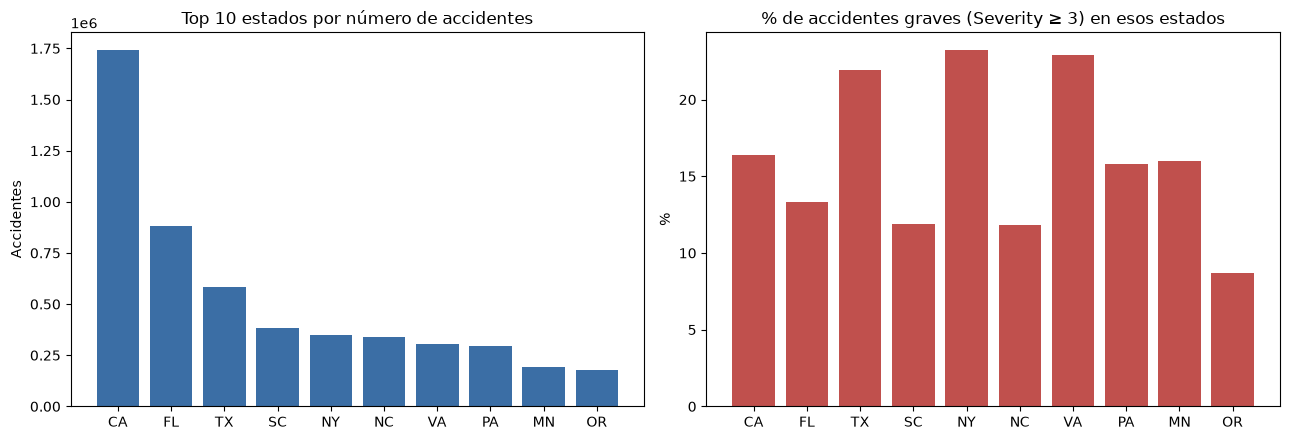

In [16]:
import matplotlib.pyplot as plt

top = (spark.read.parquet(f"{RUTA_GOLD}/agregacion_principal.parquet")
       .orderBy(F.col("n").desc()).limit(10).toPandas())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(top["State"], top["n"], color="#3b6ea5")
ax[0].set_title("Top 10 estados por número de accidentes")
ax[0].set_ylabel("Accidentes")
ax[1].bar(top["State"], top["pct_graves"], color="#c0504d")
ax[1].set_title("% de accidentes graves (Severity ≥ 3) en esos estados")
ax[1].set_ylabel("%")
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/grafico_estados.png", dpi=150)
plt.show()

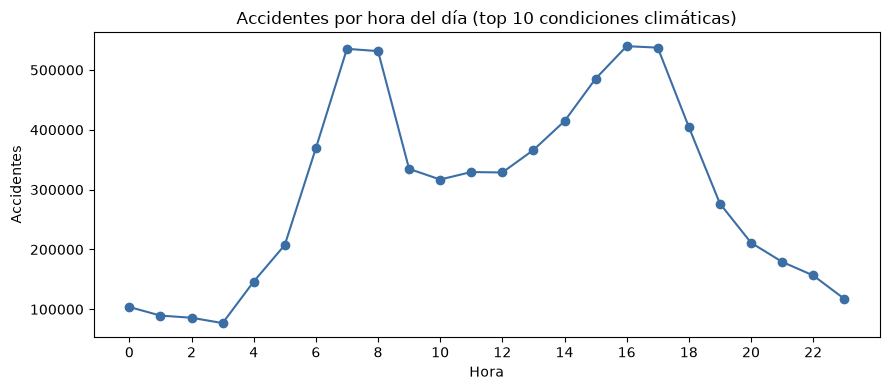

In [17]:
horas = (spark.read.parquet(f"{RUTA_GOLD}/consulta_sql.parquet")
         .groupBy("Hour").agg(F.sum("n").alias("n"), F.avg("severidad_media").alias("sev"))
         .orderBy("Hour").toPandas())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(horas["Hour"], horas["n"], marker="o", color="#3b6ea5")
ax.set_title("Accidentes por hora del día (top 10 condiciones climáticas)")
ax.set_xlabel("Hora"); ax.set_ylabel("Accidentes"); ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/grafico_horas.png", dpi=150)
plt.show()

### Respuesta a la pregunta de negocio
**¿En qué estados, horas y condiciones climáticas se concentran los accidentes y los más severos?**

- **Estados (volumen):** California, Florida y Texas concentran el 41.5 % de los accidentes; solo California aporta el 22.5 %.
- **Estados (gravedad):** la mayor proporción de accidentes graves está en Georgia (43.74 %), Illinois (36.73 %) y Michigan (29.67 %), no en los de mayor volumen. Prioridad de prevención distinta según el criterio: volumen (CA, FL, TX) o gravedad (GA, IL, MI).
- **Horas:** hay dos picos claros en las horas de traslado (7–8 h y 16–17 h), con cerca de 530 mil accidentes cada uno en las 10 condiciones climáticas principales, y un mínimo de madrugada (3 h). Sin embargo, la madrugada tiene mayor severidad media (≈2.65 con clima despejado frente a ≈2.30 en la hora pico de la mañana).
- **Clima:** con clima despejado (`Clear`) la severidad media es mayor que con nublado (`Cloudy`) en las mismas horas, por lo que, en las condiciones comparadas, el clima adverso no explica por sí solo la gravedad.
- **Hallazgos inesperados:** la severidad media desciende con los años en los principales estados (California 2.388 → 2.006 entre 2016 y 2023) y Oregon presenta una duración media de 912.8 min, muy superior al resto.
- **Acción de negocio:** concentrar vigilancia y tiempos de respuesta en las ventanas de 7–8 h y 16–17 h en CA, FL y TX para reducir volumen, y reforzar el control nocturno de velocidad y la atención prioritaria en Georgia, Illinois y Michigan, donde los accidentes son más graves.

In [18]:
# Verificación final de entregables
for carpeta in [RUTA_BRONZE, RUTA_SILVER, RUTA_GOLD]:
    n = sum(len(fs) for _, _, fs in os.walk(carpeta))
    mb = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(carpeta) for f in fs) / 1024 / 1024
    print(f"{carpeta}: {n} archivos, {mb:.1f} MB")

outputs/bronze/dataset_bronze.parquet: 48 archivos, 743.3 MB
outputs/silver/dataset_silver.parquet: 258 archivos, 545.6 MB
outputs/gold: 12 archivos, 0.0 MB
